In [1]:
from datetime import datetime
import gc
import numpy as np
import pandas as pd
import sklearn.metrics as sm
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

In [2]:
# Недельный наивный baseline
def forecast_naive(train, test):

    test = test.copy()

    last_ml = train["Volume Sold (Liters)"].iloc[-1]
    test["Forecast_Naive"] = 0.0
    test.iloc[0, test.columns.get_loc("Forecast_Naive")] = last_ml

    for i in range(1, len(test)):
        test.iloc[i, test.columns.get_loc("Forecast_Naive")] = test["Volume Sold (Liters)"].iloc[i-1]

    return test["Forecast_Naive"]

In [3]:
# Сезонный наивный baseline
def seasonal_baseline(ml_weekly, test):

    test = test.copy()

    one_week = test["Week"].iloc[0]
    idx = (ml_weekly["Week"] == one_week).idxmax()

    test["Forecast_Seasonal"] = (
        ml_weekly["Volume Sold (Liters)"].iloc[idx - 52:idx - 52 + len(test)].to_numpy()
    )
    return test["Forecast_Seasonal"]


In [4]:
# Подготовка к ML
def preparation_for_ML(ml_weekly, test, feature_cols):
    # Копируем исходный временной ряд
    ml_features = ml_weekly.copy()

    # Лаговые признаки
    for lag in [1, 2, 4]:
        ml_features[f"lag_{lag}"] = (
            ml_features["Volume Sold (Liters)"].shift(lag)
        )

    # Скользящие средние по предыдущим неделям
    for window in [4, 8]:
        ml_features[f"rolling_mean_{window}"] = (
            ml_features["Volume Sold (Liters)"]
            .shift(1)
            .rolling(window=window)
            .mean()
        )

    # Календарные признаки
    ml_features["month"] = ml_features["Week_Start"].dt.month
    ml_features["quarter"] = ml_features["Week_Start"].dt.quarter
    ml_features["week_of_year"] = (
        ml_features["Week_Start"].dt.isocalendar().week.astype(int)
    )

    print("Пропуски по признакам:")
    print(ml_features[feature_cols].isna().sum())

    print("\nРазмер ряда:", ml_features.shape)

    ml_features = ml_features.dropna(subset=feature_cols).copy()

    test_start = test["Week_Start"].min()

    train_model = ml_features[ml_features["Week_Start"] < test_start].copy()
    test_model = ml_features[ml_features["Week_Start"] >= test_start].copy()

    print("Train:", train_model.shape)
    print("Test:", test_model.shape)
    print("Начало теста:", test_model["Week_Start"].min())

    return train_model, test_model

In [5]:
def Random_Forest(train_model,test_model,feature_cols,target_col, parameters):

    test_model = test_model.copy()

    X_train = train_model[feature_cols]
    y_train = train_model[target_col]

    X_test = test_model[feature_cols]
    y_test = test_model[target_col]

    # Создаём и обучаем модель
    model_rf = RandomForestRegressor(
        n_estimators=parameters[0],
        max_depth=parameters[1],
        min_samples_leaf=parameters[2],
        random_state=parameters[3],
        n_jobs=parameters[4]
    )

    model_rf.fit(X_train, y_train)

    # Прогноз
    test_model["Forecast_RF"] = model_rf.predict(X_test)
    return model_rf, test_model["Forecast_RF"], y_test

In [6]:
def Linear_Regression(train_model,test_model,feature_cols,target_col):

    test_model = test_model.copy()

    X_train = train_model[feature_cols]
    y_train = train_model[target_col]

    X_test = test_model[feature_cols]

    model_lr = LinearRegression()
    model_lr.fit(X_train, y_train)

    test_model["Forecast_LR"] = model_lr.predict(X_test)

    return model_lr, test_model["Forecast_LR"]

In [7]:
def metrics(test,target_col,MAS):

    for model_name, mas in MAS:
        mae = sm.mean_absolute_error(
            test[target_col],
            mas
        )

        rmse = sm.root_mean_squared_error(
            test[target_col],
            mas
        )

        msd = (mas - test[target_col]).mean()

        print(f"{model_name}: MAE = {mae:.2f}, RMSE = {rmse:.2f}, MSD = {msd:.2f}")

In [8]:
def analysis_error(table_forecast):

    table_forecast = table_forecast.copy()

    models = ["Naive", "Seasonal", "RF", "LR"]
    actual = table_forecast["Volume Sold (Liters)"]

    for model in models:
        # Ошибка со знаком
        error_col = f"Error_{model}"
        table_forecast[error_col] = (
            table_forecast[f"Forecast_{model}"] - actual
        )

        # Абсолютная ошибка
        table_forecast[f"Abs_Error_{model}"] = (
            table_forecast[error_col].abs()
        )

        # Квадратичная ошибка
        table_forecast[f"Squared_Error_{model}"] = (
            table_forecast[error_col] ** 2
        )

    return table_forecast

In [9]:
def week_5(table_forecast):
    models = ["Naive", "Seasonal", "RF", "LR"]

    for model in models:
        abs_error_5 = table_forecast.sort_values(by=f"Abs_Error_{model}", ascending=False)[
            ["Week", "Volume Sold (Liters)", f"Forecast_{model}", f"Error_{model}", f"Abs_Error_{model}",
             f"Squared_Error_{model}"]].head(5)
        print("-"*40+f"{model}"+"-"*40)
        print("Долю этих пяти недель: ",
              np.sum(abs_error_5[f"Squared_Error_{model}"]) / np.sum(table_forecast[f"Squared_Error_{model}"]) * 100)
        print(abs_error_5)

In [10]:
def stat(table_forecast):

    table_forecast = table_forecast.copy()

    periods = ['Неделя падения', 'до падения', 'после падения']
    models = ["Naive", "Seasonal", "RF", "LR"]

    for model in models:
        print("-"*30+f"{model}"+"-"*30)
        for period in periods:
            stats = table_forecast[table_forecast['Period'] == period]
            print(period)
            mae = sm.mean_absolute_error(stats["Volume Sold (Liters)"], stats[f"Forecast_{model}"])
            rmse = np.sqrt(sm.mean_squared_error(stats["Volume Sold (Liters)"], stats[f"Forecast_{model}"]))
            msd = (stats[f"Forecast_{model}"] - stats["Volume Sold (Liters)"]).mean()
            print(" Кол-во недель =", len(stats), "MAE =", mae, " RMSE =", rmse, " MSD =", msd)

In [11]:
target_col = "Volume Sold (Liters)"

feature_cols = [
    "lag_1",
    "lag_2",
    "lag_4",
    "rolling_mean_4",
    "rolling_mean_8",
    "month",
    "quarter",
    "week_of_year",
]

parameters = [200, 4, 3, 42, -1]

In [12]:
ad = "Data\\processed\\ml_weekly.csv"
ml_data = pd.read_csv(ad, sep=',')

ml_data["Week_Start"] = pd.to_datetime(ml_data["Week"].str.split("/").str[0])
start_dates = ml_data['Week'].astype(str).str.split('/').str[0]
ml_data['Week'] = pd.to_datetime(start_dates).dt.to_period("W")

## Эксперимент 1

In [13]:
ml_weekly = ml_data.copy()

date = "2017-01-01"
date2 = "2014-12-31"
dt = datetime.strptime(date, "%Y-%m-%d")
dt2 = datetime.strptime(date2, "%Y-%m-%d")
ml_weekly = ml_weekly[(ml_weekly['Week_Start'] < dt) & (ml_weekly['Week_Start'] > dt2)]

In [14]:
train = ml_weekly.iloc[:83].copy()
test = ml_weekly.iloc[83:].reset_index(drop=True)

print("Обучение:", train.shape)
print(train[["Week", "Week_Start"]].head(1))
print(train[["Week", "Week_Start"]].tail(1))

print("\nТест:", test.shape)
print(test[["Week", "Week_Start"]].head(1))
print(test[["Week", "Week_Start"]].tail(1))

Обучение: (83, 4)
                    Week Week_Start
0  2015-01-05/2015-01-11 2015-01-05
                     Week Week_Start
82  2016-08-01/2016-08-07 2016-08-01

Тест: (21, 4)
                    Week Week_Start
0  2016-08-08/2016-08-14 2016-08-08
                     Week Week_Start
20  2016-12-26/2017-01-01 2016-12-26


In [15]:
train_model, test_model = preparation_for_ML(ml_weekly, test, feature_cols)
Forecast_Naive = forecast_naive(train, test)
Forecast_Seasonal = seasonal_baseline(ml_weekly, test)
model_rf, Forecast_RF , y_test = Random_Forest(train_model,test_model,feature_cols,target_col, parameters)
model_lr, Forecast_LR = Linear_Regression(train_model,test_model,feature_cols,target_col)

Forecast_LR = Forecast_LR.reset_index(drop=True)
Forecast_RF = Forecast_RF.reset_index(drop=True)

print("-"*20+"Метрики"+"-"*20)
MAS =[("Naive", Forecast_Naive),
      ("Seasonal", Forecast_Seasonal),
      ("Random_Forest", Forecast_RF),
      ("Linear_Regression", Forecast_LR)]

metrics(test,target_col,MAS)

Пропуски по признакам:
lag_1             1
lag_2             2
lag_4             4
rolling_mean_4    4
rolling_mean_8    8
month             0
quarter           0
week_of_year      0
dtype: int64

Размер ряда: (104, 12)
Train: (75, 12)
Test: (21, 12)
Начало теста: 2016-08-08 00:00:00
--------------------Метрики--------------------
Naive: MAE = 7289.44, RMSE = 15066.26, MSD = 3591.70
Seasonal: MAE = 74798.29, RMSE = 81511.61, MSD = 71834.49
Random_Forest: MAE = 84920.64, RMSE = 89575.51, MSD = 84920.64
Linear_Regression: MAE = 141103.43, RMSE = 152167.40, MSD = 140726.59


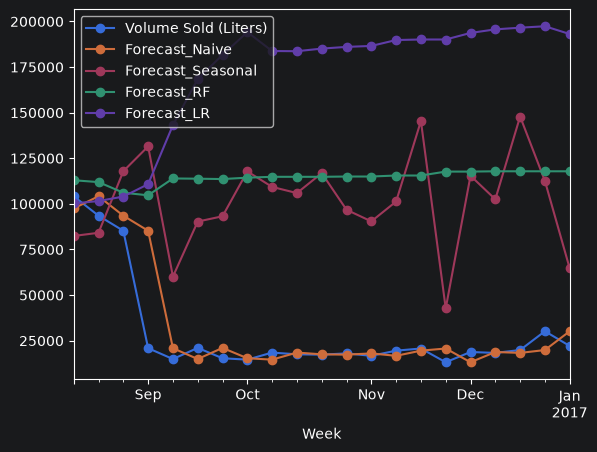

In [16]:
table_forecast = pd.concat([test[['Week', 'Week_Start', 'Volume Sold (Liters)']], pd.DataFrame(Forecast_Naive), pd.DataFrame(Forecast_Seasonal), pd.DataFrame(Forecast_RF), pd.DataFrame(Forecast_LR)], axis=1)

table_forecast.plot(x='Week', y=['Volume Sold (Liters)', 'Forecast_Naive', "Forecast_Seasonal", "Forecast_RF", "Forecast_LR"], kind='line', marker='o')
plt.show()

In [17]:
table_forecast = analysis_error(table_forecast)
week_5(table_forecast)

----------------------------------------Naive----------------------------------------
Долю этих пяти недель:  94.37576533582224
                     Week  Volume Sold (Liters)  Forecast_Naive  Error_Naive  \
3   2016-08-29/2016-09-04              20880.60        85264.50     64383.90   
1   2016-08-15/2016-08-21              93513.41       104167.92     10654.51   
19  2016-12-19/2016-12-25              30186.99        19874.72    -10312.27   
2   2016-08-22/2016-08-28              85264.50        93513.41      8248.91   
20  2016-12-26/2017-01-01              22090.85        30186.99      8096.14   

    Abs_Error_Naive  Squared_Error_Naive  
3          64383.90         4.145287e+09  
1          10654.51         1.135186e+08  
19         10312.27         1.063429e+08  
2           8248.91         6.804452e+07  
20          8096.14         6.554748e+07  
----------------------------------------Seasonal----------------------------------------
Долю этих пяти недель:  46.39589290827475
  

In [18]:
crash_date = pd.to_datetime('2016-08-29')

conditions = [
    table_forecast['Week_Start'] == crash_date,   # 1. Ровно неделя падения
    table_forecast['Week_Start'] < crash_date,    # 2. До падения
    table_forecast['Week_Start'] > crash_date     # 3. После падения
]

# Что присвоить, если условие выполнено
choices = [
    'Неделя падения',
    'до падения',
    'после падения'
]

# Применяем
table_forecast['Period'] = np.select(conditions, choices, default='Неизвестно')
stat(table_forecast)

------------------------------Naive------------------------------
Неделя падения
 Кол-во недель = 1 MAE = 64383.9  RMSE = 64383.9  MSD = 64383.9
до падения
 Кол-во недель = 3 MAE = 8518.233333333332  RMSE = 8675.686815589874  MSD = 4084.0466666666666
после падения
 Кол-во недель = 17 MAE = 3714.097058823529  RMSE = 4824.868414325807  MSD = -71.19117647058823
------------------------------Seasonal------------------------------
Неделя падения
 Кол-во недель = 1 MAE = 110644.22  RMSE = 110644.22  MSD = 110644.22
до падения
 Кол-во недель = 3 MAE = 21255.77  RMSE = 23287.718247211338  MSD = 509.1233333333318
после падения
 Кол-во недель = 17 MAE = 82138.39117647058  RMSE = 85974.65270078341  MSD = 82138.39117647058
------------------------------RF------------------------------
Неделя падения
 Кол-во недель = 1 MAE = 83823.7617468661  RMSE = 83823.7617468661  MSD = 83823.7617468661
до падения
 Кол-во недель = 3 MAE = 16024.225626890451  RMSE = 16850.11103214347  MSD = 16024.225626890451
пос

In [19]:
del ml_weekly, train, test, train_model, test_model, Forecast_Naive, Forecast_Seasonal, model_rf, Forecast_RF , y_test, model_lr, Forecast_LR, table_forecast
gc.collect()

5881

## Эксперимент 2

In [20]:
ml_weekly = ml_data.copy()
print(ml_weekly)
train = ml_weekly[ml_weekly["Week_Start"] < "2017-01-02"].copy()
test = ml_weekly[ml_weekly["Week_Start"] >= "2017-01-02"].copy().reset_index(drop=True)

print("Обучение:", train.shape)
print(train[["Week", "Week_Start"]].head(1))
print(train[["Week", "Week_Start"]].tail(1))

print("\nТест:", test.shape)
print(test[["Week", "Week_Start"]].head(1))
print(test[["Week", "Week_Start"]].tail(1))

                      Week  Volume Sold (Liters)  Year Week_Start
0    2015-01-05/2015-01-11              85395.63  2015 2015-01-05
1    2015-01-12/2015-01-18             107265.54  2015 2015-01-12
2    2015-01-19/2015-01-25              48501.05  2015 2015-01-19
3    2015-01-26/2015-02-01              85677.94  2015 2015-01-26
4    2015-02-02/2015-02-08              89135.13  2015 2015-02-02
..                     ...                   ...   ...        ...
142  2017-09-25/2017-10-01              14817.71  2017 2017-09-25
143  2017-10-02/2017-10-08              20523.49  2017 2017-10-02
144  2017-10-09/2017-10-15              18737.14  2017 2017-10-09
145  2017-10-16/2017-10-22              18092.09  2017 2017-10-16
146  2017-10-23/2017-10-29              19364.17  2017 2017-10-23

[147 rows x 4 columns]
Обучение: (104, 4)
                    Week Week_Start
0  2015-01-05/2015-01-11 2015-01-05
                      Week Week_Start
103  2016-12-26/2017-01-01 2016-12-26

Тест: (43, 4)
  

In [21]:
train_model, test_model = preparation_for_ML(ml_weekly, test, feature_cols)
Forecast_Naive = forecast_naive(train, test)
Forecast_Seasonal = seasonal_baseline(ml_weekly, test)
model_rf, Forecast_RF , y_test = Random_Forest(train_model,test_model,feature_cols,target_col, parameters)
model_lr, Forecast_LR = Linear_Regression(train_model,test_model,feature_cols,target_col)

Forecast_LR = Forecast_LR.reset_index(drop=True)
Forecast_RF = Forecast_RF.reset_index(drop=True)

print("-"*20+"Метрики"+"-"*20)
MAS =[("Naive", Forecast_Naive),
      ("Seasonal", Forecast_Seasonal),
      ("Random_Forest", Forecast_RF),
      ("Linear_Regression", Forecast_LR)]

metrics(test,target_col,MAS)

Пропуски по признакам:
lag_1             1
lag_2             2
lag_4             4
rolling_mean_4    4
rolling_mean_8    8
month             0
quarter           0
week_of_year      0
dtype: int64

Размер ряда: (147, 12)
Train: (96, 12)
Test: (43, 12)
Начало теста: 2017-01-02 00:00:00
--------------------Метрики--------------------
Naive: MAE = 2342.53, RMSE = 3210.99, MSD = 63.41
Seasonal: MAE = 64461.45, RMSE = 74088.86, MSD = 64180.47
Random_Forest: MAE = 1768.31, RMSE = 2150.79, MSD = 20.27
Linear_Regression: MAE = 5600.32, RMSE = 7027.19, MSD = 4905.85


In [22]:
# Важность признаков Random Forest
feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": model_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print(feature_importance)

          Feature  Importance
0           lag_1    0.535511
1  rolling_mean_4    0.188120
2  rolling_mean_8    0.126614
3           lag_2    0.088009
4           lag_4    0.036590
5    week_of_year    0.023058
6           month    0.002072
7         quarter    0.000026


In [23]:
from sklearn.inspection import permutation_importance

# Перестановочная важность на тестовой выборке
perm_importance = permutation_importance(
    model_rf,
    test_model[feature_cols],
    test_model[target_col],
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

# Формируем таблицу результатов
permutation_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance_Mean": perm_importance.importances_mean,
    "Importance_Std": perm_importance.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

print(permutation_df)

          Feature  Importance_Mean  Importance_Std
0  rolling_mean_4        41.693880       43.355970
1           lag_1        28.894350       46.199918
2           lag_4        11.899894       52.684374
3           lag_2         2.635672        5.195069
4    week_of_year         2.442708        1.454733
5         quarter         2.350680        1.278525
6           month         1.371781        0.790332
7  rolling_mean_8         0.595247        6.358308


In [24]:
perm_table = pd.DataFrame()
for sign in perm_importance.importances:
    sign += 1768.31
    perm_table = pd.concat([perm_table, pd.DataFrame(sign)], axis=1)

perm_table.columns = ["lag_1",
    "lag_2",
    "lag_4",
    "rolling_mean_4",
    "rolling_mean_8",
    "month",
    "quarter",
    "week_of_year"]
print(perm_table)

summary = pd.DataFrame({
    "Feature": perm_table.columns,
    "MAE_mean": perm_table.mean().values,
    "MAE_std": perm_table.std().values,
    "MAE_min": perm_table.min(),
    "MAE_max": perm_table.max()
})

print(summary)

          lag_1        lag_2        lag_4  rolling_mean_4  rolling_mean_8  \
0   1795.957421  1781.961912  1839.380179     1844.617860     1780.007467   
1   1824.625498  1767.523654  1722.275399     1790.169219     1771.701927   
2   1873.388151  1767.143311  1739.480016     1792.923208     1772.126150   
3   1828.387606  1771.875878  1793.860313     1825.431190     1762.923966   
4   1795.932979  1766.680172  1727.893744     1802.446314     1764.206186   
5   1786.844584  1765.061010  1745.764301     1802.025260     1771.436668   
6   1853.776988  1775.125369  1863.857609     1904.729874     1772.707514   
7   1860.059392  1763.957389  1796.128200     1870.428071     1771.333272   
8   1814.222981  1771.410700  1850.613486     1889.566077     1770.736138   
9   1805.329344  1764.738246  1686.745313     1778.977090     1768.738199   
10  1760.494250  1778.051972  1671.851533     1765.209796     1769.196276   
11  1804.882265  1771.896251  1788.297155     1855.512039     1773.699218   

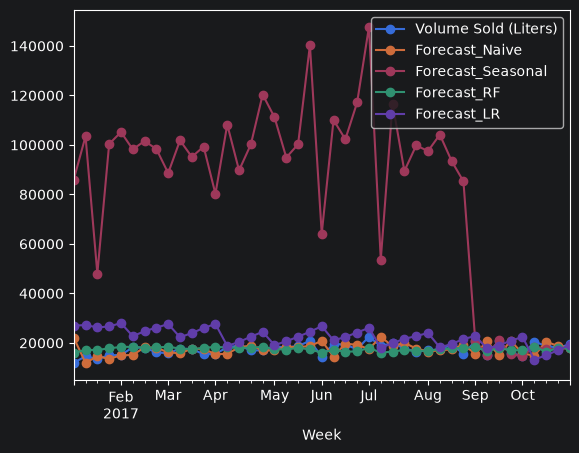

In [25]:
table_forecast = pd.concat([test[['Week', 'Week_Start', 'Volume Sold (Liters)']], pd.DataFrame(Forecast_Naive), pd.DataFrame(Forecast_Seasonal), pd.DataFrame(Forecast_RF), pd.DataFrame(Forecast_LR)], axis=1)

table_forecast.plot(x='Week', y=['Volume Sold (Liters)', 'Forecast_Naive', "Forecast_Seasonal", "Forecast_RF", "Forecast_LR"], kind='line', marker='o')
plt.show()

In [26]:
table_forecast = analysis_error(table_forecast)
week_5(table_forecast)

----------------------------------------Naive----------------------------------------
Долю этих пяти недель:  54.243758447503545
                     Week  Volume Sold (Liters)  Forecast_Naive  Error_Naive  \
0   2017-01-02/2017-01-08              11958.88        22090.85     10131.97   
21  2017-05-29/2017-06-04              14455.02        20835.94      6380.92   
36  2017-09-11/2017-09-17              20851.26        15037.62     -5813.64   
39  2017-10-02/2017-10-08              20523.49        14817.71     -5705.78   
35  2017-09-04/2017-09-10              15037.62        20583.99      5546.37   

    Abs_Error_Naive  Squared_Error_Naive  
0          10131.97         1.026568e+08  
21          6380.92         4.071614e+07  
36          5813.64         3.379841e+07  
39          5705.78         3.255593e+07  
35          5546.37         3.076222e+07  
----------------------------------------Seasonal----------------------------------------
Долю этих пяти недель:  25.38569876416562
 

In [27]:
del ml_weekly, train, test, train_model, test_model, Forecast_Naive, Forecast_Seasonal, model_rf, Forecast_RF , y_test, model_lr, Forecast_LR, table_forecast
gc.collect()

7965

## Эксперимент 3

In [28]:
ml_weekly = ml_data.copy()
train = ml_weekly[ml_weekly["Week_Start"] < "2016-08-29"].copy()
test = ml_weekly[ml_weekly["Week_Start"] >= "2017-01-02"].copy().reset_index(drop=True)

print("Обучение:", train.shape)
print(train[["Week", "Week_Start"]].head(1))
print(train[["Week", "Week_Start"]].tail(1))

print("\nТест:", test.shape)
print(test[["Week", "Week_Start"]].head(1))
print(test[["Week", "Week_Start"]].tail(1))

Обучение: (86, 4)
                    Week Week_Start
0  2015-01-05/2015-01-11 2015-01-05
                     Week Week_Start
85  2016-08-22/2016-08-28 2016-08-22

Тест: (43, 4)
                    Week Week_Start
0  2017-01-02/2017-01-08 2017-01-02
                     Week Week_Start
42  2017-10-23/2017-10-29 2017-10-23


In [29]:
train_model, test_model = preparation_for_ML(ml_weekly, test, feature_cols)

train_model = train_model[
    train_model["Week_Start"] < "2016-08-29"
].copy()

print("Обучение:", train_model.shape)
print(train_model["Week_Start"].min(), train_model["Week_Start"].max())

print("\nТест:", test_model.shape)
print(test_model["Week_Start"].min(), test_model["Week_Start"].max())

Пропуски по признакам:
lag_1             1
lag_2             2
lag_4             4
rolling_mean_4    4
rolling_mean_8    8
month             0
quarter           0
week_of_year      0
dtype: int64

Размер ряда: (147, 12)
Train: (96, 12)
Test: (43, 12)
Начало теста: 2017-01-02 00:00:00
Обучение: (78, 12)
2015-03-02 00:00:00 2016-08-22 00:00:00

Тест: (43, 12)
2017-01-02 00:00:00 2017-10-23 00:00:00


In [30]:
Forecast_Naive = forecast_naive(train, test)
Forecast_Seasonal = seasonal_baseline(ml_weekly, test)
model_rf, Forecast_RF , y_test = Random_Forest(train_model,test_model,feature_cols,target_col, parameters)
model_lr, Forecast_LR = Linear_Regression(train_model,test_model,feature_cols,target_col)

Forecast_LR = Forecast_LR.reset_index(drop=True)
Forecast_RF = Forecast_RF.reset_index(drop=True)

print("-"*20+"Метрики"+"-"*20)
MAS =[("Naive", Forecast_Naive),
      ("Seasonal", Forecast_Seasonal),
      ("Random_Forest", Forecast_RF),
      ("Linear_Regression", Forecast_LR)]

metrics(test,target_col,MAS)

--------------------Метрики--------------------
Naive: MAE = 3811.69, RMSE = 11527.93, MSD = 1532.57
Seasonal: MAE = 64461.45, RMSE = 74088.86, MSD = 64180.47
Random_Forest: MAE = 95478.41, RMSE = 95532.37, MSD = 95478.41
Linear_Regression: MAE = 163733.58, RMSE = 163846.83, MSD = 163733.58


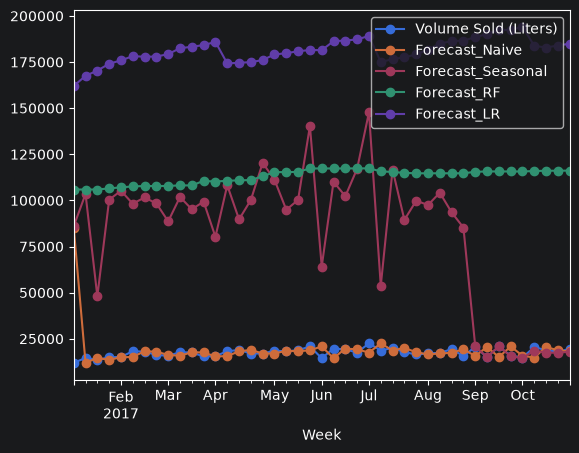

In [31]:
table_forecast = pd.concat([test[['Week', 'Week_Start', 'Volume Sold (Liters)']], pd.DataFrame(Forecast_Naive), pd.DataFrame(Forecast_Seasonal), pd.DataFrame(Forecast_RF), pd.DataFrame(Forecast_LR)], axis=1)

table_forecast.plot(x='Week', y=['Volume Sold (Liters)', 'Forecast_Naive', "Forecast_Seasonal", "Forecast_RF", "Forecast_LR"], kind='line', marker='o')
plt.show()

In [32]:
table_forecast = analysis_error(table_forecast)
week_5(table_forecast)

----------------------------------------Naive----------------------------------------
Долю этих пяти недель:  96.45002282393557
                     Week  Volume Sold (Liters)  Forecast_Naive  Error_Naive  \
0   2017-01-02/2017-01-08              11958.88        85264.50     73305.62   
21  2017-05-29/2017-06-04              14455.02        20835.94      6380.92   
36  2017-09-11/2017-09-17              20851.26        15037.62     -5813.64   
39  2017-10-02/2017-10-08              20523.49        14817.71     -5705.78   
35  2017-09-04/2017-09-10              15037.62        20583.99      5546.37   

    Abs_Error_Naive  Squared_Error_Naive  
0          73305.62         5.373714e+09  
21          6380.92         4.071614e+07  
36          5813.64         3.379841e+07  
39          5705.78         3.255593e+07  
35          5546.37         3.076222e+07  
----------------------------------------Seasonal----------------------------------------
Долю этих пяти недель:  25.38569876416562
  